# Target 直接推理 vs DSpark：每 token 平均耗时对比

同一个 `Qwen3.5-0.8B-Base`，同一批 prompt，温度 1.0，纯温度采样，每条生成最多 96 个 token（遇到 EOS 提前停止）。
计时只算 decode，prefill 排除。两种模式各自跑若干条 prompt，取中位数。

- **baseline**：标准自回归，每个 token 一次 Target 前向
- **DSpark**：每轮 drafter 出 7 个草稿 + 一次 Target 验证；部分接受时回滚（GDN 状态不可裁剪，用 deepcopy 快照）并重放被接受前缀 + 修正 token

指标：
- `ms/token`：总 decode 时间 ÷ 生成的 token 数
- `accepted/round`：每轮实际被接受的草稿数（不含 anchor 和修正 token）
- `fwd/round`：每轮 Target 前向次数，全接受时 1 次，部分接受时 2 次

**理论盈亏点**：baseline 每 token 1 次前向。DSpark 每轮 2 次前向（部分接受）加 drafter 开销，所以每轮要接受约 2 个草稿才平价；全接受时 1 次前向换 8 个 token，才有明显收益。

In [1]:
import sys, time, statistics, json
import torch
sys.path.insert(0, '/home/dev/KAP/src4dspark')

from transformers import AutoModelForImageTextToText, AutoTokenizer
from dspark_paper import DSparkDrafter, load
from dspark_e2e import DSparkDecode, baseline_generate

P = '/home/dev/KAP/parameter/target/Qwen3.5-0.8B-Base-original'
DEV = 'cuda:0'
TEMP = 1.0
MAX_NEW = 96
PROMPTS = [
    'What is 17 * 24? Answer briefly.',
    'Explain why the sky is blue.',
    'Write a Python function that reverses a string.',
    'List three fruits and their colors.',
    'A train travels 120 km in 1.5 hours. What is its average speed?',
    'Summarize the plot of Romeo and Juliet in three sentences.',
]
DRAFT_DTYPE = torch.float32          # 训练和离线评测都用 fp32；改成 bfloat16 可测速度差异

tok = AutoTokenizer.from_pretrained(P)
m = AutoModelForImageTextToText.from_pretrained(P, dtype=torch.bfloat16, device_map=DEV).eval()
d = DSparkDrafter(m, device=DEV, dtype=DRAFT_DTYPE)
load(d, '/home/dev/KAP/parameter/draft/dspark_pb/dflash_pb_best.pt'); d.eval()
print('drafter', d.n_params, 'params,', str(DRAFT_DTYPE).split('.')[-1])

def ids_of(p):
    return tok(tok.apply_chat_template([{'role': 'user', 'content': p}],
                                       tokenize=False, add_generation_prompt=True),
               add_special_tokens=False)['input_ids']

/home/dev/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Current Python version 3.10 is below the recommended 3.11 version. It is recommended to upgrade to Python 3.11 or higher for the best experience.


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Loading weights:  42%|████▏     | 201/473 [00:00<00:00, 1998.67it/s]

Loading weights: 100%|██████████| 473/473 [00:00<00:00, 2632.76it/s]

drafter 135157889 params, float32


In [2]:
# 预热：第一次前向包含 kernel 编译和显存分配，不计入
_ = baseline_generate(m, tok, ids_of(PROMPTS[0]), 8, TEMP, torch.Generator(device=DEV).manual_seed(0))
_ = DSparkDecode(m, d, tok, temperature=TEMP, seed=0).generate(ids_of(PROMPTS[0]), max_new_tokens=8)
torch.cuda.synchronize()
print('warm-up done')

warm-up done


## 测量

In [3]:
rows = []
for i, p in enumerate(PROMPTS):
    ids = ids_of(p)
    g = torch.Generator(device=DEV).manual_seed(i)
    btok, bt = baseline_generate(m, tok, ids, MAX_NEW, TEMP, g)
    g = torch.Generator(device=DEV).manual_seed(i)
    eng = DSparkDecode(m, d, tok, temperature=TEMP, seed=i)
    dtok, st = eng.generate(ids, max_new_tokens=MAX_NEW)
    tt = st['draft_ms'] + st['verify_ms'] + st['replay_ms']
    rows.append(dict(
        prompt=p[:40], n_prompt=len(ids), n_base=len(btok), n_dspark=st['tokens'],
        base_ms=bt * 1e3 / len(btok), dspark_ms=tt / st['tokens'],
        rounds=st['rounds'], acc=sum(st['accepted']) / st['rounds'],
        fwd=st['fwds'] / st['rounds'], all_acc=st['all_accepted'],
        draft_ms=st['draft_ms'], verify_ms=st['verify_ms'], replay_ms=st['replay_ms']))
    r = rows[-1]
    print('%-42s base %5.2f ms/tok (%3d)   dspark %5.2f ms/tok (%3d)   acc/round %.2f  fwd/round %.2f'
          % (r['prompt'], r['base_ms'], r['n_base'], r['dspark_ms'], r['n_dspark'], r['acc'], r['fwd']))

mb = statistics.median(r['base_ms'] for r in rows)
md = statistics.median(r['dspark_ms'] for r in rows)
mac = statistics.median(r['acc'] for r in rows)
mf = statistics.median(r['fwd'] for r in rows)
print()
print('median  baseline %.2f ms/token   DSpark %.2f ms/token' % (mb, md))
print('ratio   baseline/DSpark = %.3f   (>1 表示 DSpark 更快)' % (mb / md))
print('median  accepted/round %.2f   target forwards/round %.2f' % (mac, mf))
print('每轮前向能平价的条件: accepted/round >= fwd/round - 1 = %.2f' % (mf - 1))

What is 17 * 24? Answer briefly.           base 16.74 ms/tok ( 15)   dspark 21.66 ms/tok ( 15)   acc/round 1.00  fwd/round 2.00


Explain why the sky is blue.               base 17.64 ms/tok ( 96)   dspark 27.91 ms/tok ( 96)   acc/round 0.29  fwd/round 2.00


Write a Python function that reverses a    base 17.60 ms/tok ( 96)   dspark 18.78 ms/tok ( 96)   acc/round 1.43  fwd/round 2.00


List three fruits and their colors.        base 17.33 ms/tok ( 69)   dspark 23.90 ms/tok ( 96)   acc/round 0.67  fwd/round 2.00


A train travels 120 km in 1.5 hours. Wha   base 17.58 ms/tok ( 96)   dspark 18.33 ms/tok ( 94)   acc/round 1.48  fwd/round 2.00


Summarize the plot of Romeo and Juliet i   base 17.30 ms/tok ( 64)   dspark 28.33 ms/tok ( 97)   acc/round 0.26  fwd/round 2.00

median  baseline 17.46 ms/token   DSpark 22.78 ms/token
ratio   baseline/DSpark = 0.766   (>1 表示 DSpark 更快)
median  accepted/round 0.83   target forwards/round 2.00
每轮前向能平价的条件: accepted/round >= fwd/round - 1 = 1.00


## 图

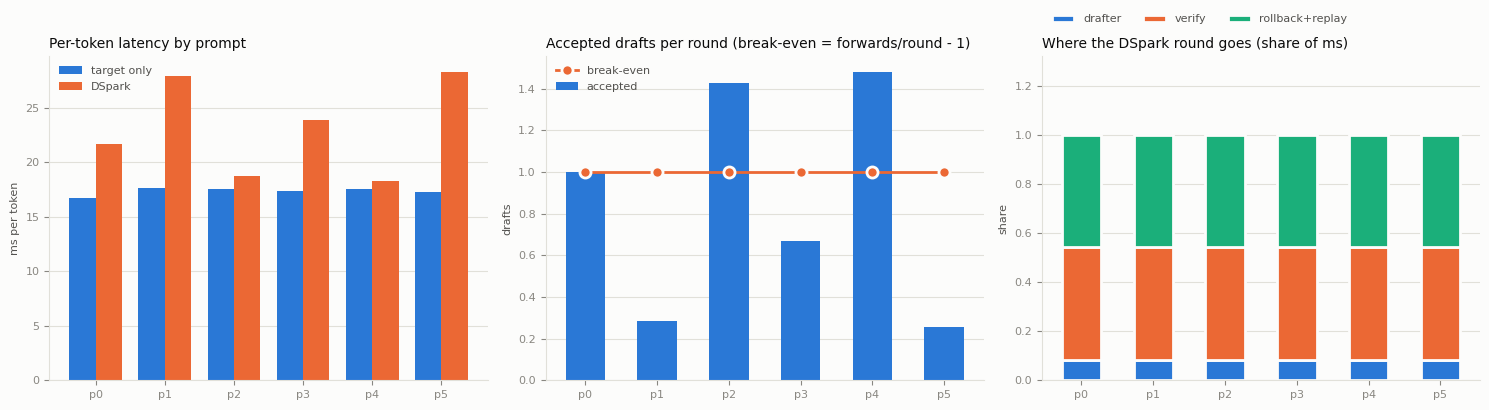

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

SURF, INK, INK2, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
BLUE, ORANGE = '#2a78d6', '#eb6834'


def style(ax, title, ylabel):
    ax.set_facecolor(SURF)
    ax.set_title(title, loc='left', fontsize=10, color=INK)
    ax.set_ylabel(ylabel, fontsize=8, color=INK2)
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'):
        ax.spines[s].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=8)


fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), facecolor=SURF)
x = list(range(len(rows)))
ax = axs[0]
style(ax, 'Per-token latency by prompt', 'ms per token')
w = 0.38
ax.bar([i - w / 2 for i in x], [r['base_ms'] for r in rows], w, color=BLUE, label='target only')
ax.bar([i + w / 2 for i in x], [r['dspark_ms'] for r in rows], w, color=ORANGE, label='DSpark')
ax.set_xticks(x)
ax.set_xticklabels([f'p{i}' for i in x], color=MUTED, fontsize=8)
ax.legend(frameon=False, fontsize=8, labelcolor=INK2)

ax = axs[1]
style(ax, 'Accepted drafts per round (break-even = forwards/round - 1)', 'drafts')
ax.bar(x, [r['acc'] for r in rows], 0.55, color=BLUE, label='accepted')
ax.plot(x, [r['fwd'] - 1 for r in rows], color=ORANGE, lw=2, marker='o', ms=8, mec=SURF, mew=2,
        label='break-even')
ax.set_xticks(x)
ax.set_xticklabels([f'p{i}' for i in x], color=MUTED, fontsize=8)
ax.legend(frameon=False, fontsize=8, labelcolor=INK2)

ax = axs[2]
style(ax, 'Where the DSpark round goes (share of ms)', 'share')
tot = [r['draft_ms'] + r['verify_ms'] + r['replay_ms'] for r in rows]
parts = [([r['draft_ms'] / t for r, t in zip(rows, tot)], 'drafter', BLUE),
         ([r['verify_ms'] / t for r, t in zip(rows, tot)], 'verify', ORANGE),
         ([r['replay_ms'] / t for r, t in zip(rows, tot)], 'rollback+replay', '#1baf7a')]
bottom = [0.0] * len(rows)
for vals, name, col in parts:
    ax.bar(x, vals, 0.55, bottom=bottom, color=col, label=name, edgecolor=SURF, linewidth=2)
    bottom = [b + v for b, v in zip(bottom, vals)]
ax.set_xticks(x)
ax.set_xticklabels([f'p{i}' for i in x], color=MUTED, fontsize=8)
ax.set_ylim(0, 1.32)
ax.legend(frameon=False, fontsize=8, labelcolor=INK2, loc='upper left', ncol=3,
          bbox_to_anchor=(0, 1.16))
fig.tight_layout()

In [5]:
with open('/home/dev/KAP/data/pb_dspark/latency_bench.json', 'w') as f:
    json.dump({'rows': rows, 'median': {'base_ms': mb, 'dspark_ms': md, 'ratio': mb / md,
                                        'acc_per_round': mac, 'fwd_per_round': mf},
               'config': {'temp': TEMP, 'max_new': MAX_NEW, 'draft_dtype': str(DRAFT_DTYPE)}}, f, indent=2)
print('saved /home/dev/KAP/data/pb_dspark/latency_bench.json')

saved /home/dev/KAP/data/pb_dspark/latency_bench.json
